In [1]:
import os
import pandas as pd


In [2]:
from common.configuration import DatasetPath, species_classes_map_all, species_by_familia, species_by_ordo
from common.stats import calculate_confusion_matrix, plot_confusion_matrix

In [3]:
all_classes = list(species_classes_map_all.keys())
all_classes

['Acer',
 'Alnus',
 'Apiaceae',
 'Artemisia',
 'Betula',
 'Chenopodiaceae',
 'Corylus',
 'Picea',
 'Pinus',
 'Plantago',
 'Poaceae',
 'Populus tremula',
 'Quercus',
 'Rumex',
 'Salix',
 'Tilia',
 'Urtica',
 'Ulmus',
 'Ambrosia',
 'Taraxacum',
 'Malus',
 'Unknown']

In [4]:
expert_estimation_excel_path = os.path.join(DatasetPath.real_historical_samples, "manual_analysis.xlsx")
expert_estimation_df = pd.read_excel(expert_estimation_excel_path, index_col=0).rename(columns={"Populus": "Populus tremula"}).fillna(0)
expert_estimation_df

,Corylus,Populus tremula,Alnus,Betula,Urtica,Salix,Acer,Ulmus,Pinus,Picea,Tilia,Plantago,Gramineae,Artemisia,Ambrosia,Chenopodiaceae,Apiaceae,Unknown,Rumex,Quercus
date,,,,,,,,,,,,,,,,,,,,
april 10,72,178,150,6,1,0,0,0,0,0,0,0,0,0,0,0,0,6,0,0.0
april 12,30,82,61,5,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0.0
april 16,22,61,50,0,0,0,0,0,1,0,0,0,0,1,0,0,0,1,0,0.0
april 18,57,149,166,13,0,4,0,0,0,0,0,0,0,0,0,1,0,6,0,0.0
may 1,0,0,1,447,10,749,228,0,1,18,1,0,0,1,0,1,0,0,0,0.0
may 21,0,0,19,16,10,0,27,0,0,0,0,0,0,1,2,5,0,0,0,0.0
june 10,0,0,1,7,29,2,5,4,2,0,0,247,27,1,0,1,0,0,0,0.0
june 17,0,0,0,0,19,0,0,5,0,0,0,340,4,5,0,3,0,0,0,0.0
june 25,10,0,1,11,42,0,0,2,0,0,0,82,19,7,0,4,0,0,0,0.0


In [5]:
model_prediction_path = "Save/historical_predictions_summary.csv"
model_prediction_df = pd.read_csv(model_prediction_path, index_col=0).fillna(0)
model_prediction_df

,Corylus,Populus tremula,Betula,Pinus,Chenopodiaceae,Poaceae,Alnus,Acer,Picea,Ambrosia,Rumex,Artemisia,Unknown,Salix,Quercus,Ulmus,Tilia,Urtica,Apiaceae,Plantago
april 10,3.0,171.0,197.0,3.0,3,2.0,7.0,10.0,1.0,3.0,2.0,3.0,1.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0
april 12,5.0,80.0,82.0,2.0,2,1.0,2.0,2.0,1.0,3.0,0.0,3.0,1.0,0.0,1.0,4.0,3.0,1.0,0.0,0.0
april 16,8.0,63.0,59.0,5.0,1,0.0,6.0,2.0,1.0,7.0,0.0,3.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0
april 18,4.0,136.0,191.0,4.0,6,4.0,4.0,3.0,0.0,2.0,2.0,5.0,5.0,2.0,4.0,5.0,4.0,1.0,0.0,0.0
august 1,8.0,1.0,4.0,1.0,112,61.0,1.0,5.0,1.0,5.0,0.0,3.0,2.0,1.0,0.0,9.0,2.0,517.0,3.0,16.0
august 15,0.0,0.0,1.0,0.0,74,0.0,0.0,1.0,0.0,4.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,103.0,1.0,1.0
august 16,0.0,0.0,1.0,3.0,161,0.0,0.0,2.0,0.0,4.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,37.0,0.0,0.0
august 25,2.0,2.0,4.0,2.0,101,5.0,5.0,11.0,0.0,5.0,0.0,1.0,2.0,4.0,0.0,6.0,1.0,53.0,1.0,3.0
august 27,5.0,2.0,2.0,0.0,2,0.0,4.0,10.0,0.0,2.0,1.0,12.0,2.0,3.0,0.0,2.0,1.0,14.0,0.0,2.0
august 28,4.0,2.0,4.0,2.0,7,2.0,8.0,35.0,1.0,12.0,0.0,22.0,1.0,0.0,2.0,17.0,5.0,19.0,0.0,2.0


In [6]:
def analyze_performance_sample_data(true_labels: dict, pred_labels: dict, subtitle: str, all_classes: list[str], mapper: dict = None, plot=False):
    if mapper is not None:
        mapped_true_labels = {}
        mapped_pred_labels = {}
        for new_class in mapper.keys():
            mapped_true_labels[new_class] = sum([true_labels[x] for x in mapper[new_class] if x in true_labels])
            mapped_pred_labels[new_class] = sum([pred_labels[x] for x in mapper[new_class] if x in pred_labels])
        true_labels = mapped_true_labels
        pred_labels = mapped_pred_labels
    print("---Sample test---")
    print(
        f"True Total objets: {sum(true_labels.values())}, data: {true_labels}")
    print("-" * 10)
    print(
        f"Pred Total objets: {sum(pred_labels.values())}, data: {pred_labels}")
    confusion_matrices_df = calculate_confusion_matrix(
        true_labels, pred_labels, all_classes)
    
    if plot:
        plot_confusion_matrix(
            confusion_matrices_df.iloc[:, 0:3], subtitle=subtitle)
        for k in true_labels.keys():
            if true_labels[k] != 0:
                print(k, round(confusion_matrices_df["TP"].to_dict().get(
                    k, 0) / true_labels[k], 3))
            
    return confusion_matrices_df


In [7]:
def evaluate_aggregate_metrics(confusion_matrices_df: pd.DataFrame):
    total_samples = (confusion_matrices_df["TP"].sum() + confusion_matrices_df["FP"].sum())
    f1_score = 2 * confusion_matrices_df["TP"].sum() / (2 * confusion_matrices_df["TP"].sum() + confusion_matrices_df["FP"].sum() + confusion_matrices_df["FN"].sum())
    print(f"F1 Score: {f1_score}")


## Classification on Genus level

---Sample test---
True Total objets: 413.0, data: {'Corylus': 72.0, 'Populus tremula': 178.0, 'Alnus': 150.0, 'Betula': 6.0, 'Urtica': 1.0, 'Salix': 0.0, 'Acer': 0.0, 'Ulmus': 0.0, 'Pinus': 0.0, 'Picea': 0.0, 'Tilia': 0.0, 'Plantago': 0.0, 'Gramineae': 0.0, 'Artemisia': 0.0, 'Ambrosia': 0.0, 'Chenopodiaceae': 0.0, 'Apiaceae': 0.0, 'Unknown': 6.0, 'Rumex': 0.0, 'Quercus': 0.0}
----------
Pred Total objets: 410.0, data: {'Corylus': 3.0, 'Populus tremula': 171.0, 'Betula': 197.0, 'Pinus': 3.0, 'Chenopodiaceae': 3.0, 'Poaceae': 2.0, 'Alnus': 7.0, 'Acer': 10.0, 'Picea': 1.0, 'Ambrosia': 3.0, 'Rumex': 2.0, 'Artemisia': 3.0, 'Unknown': 1.0, 'Salix': 1.0, 'Quercus': 1.0, 'Ulmus': 2.0, 'Tilia': 0.0, 'Urtica': 0.0, 'Apiaceae': 0.0, 'Plantago': 0.0}
---Sample test---
True Total objets: 181.0, data: {'Corylus': 30.0, 'Populus tremula': 82.0, 'Alnus': 61.0, 'Betula': 5.0, 'Urtica': 0.0, 'Salix': 0.0, 'Acer': 0.0, 'Ulmus': 0.0, 'Pinus': 0.0, 'Picea': 0.0, 'Tilia': 0.0, 'Plantago': 0.0, 'Gramineae': 

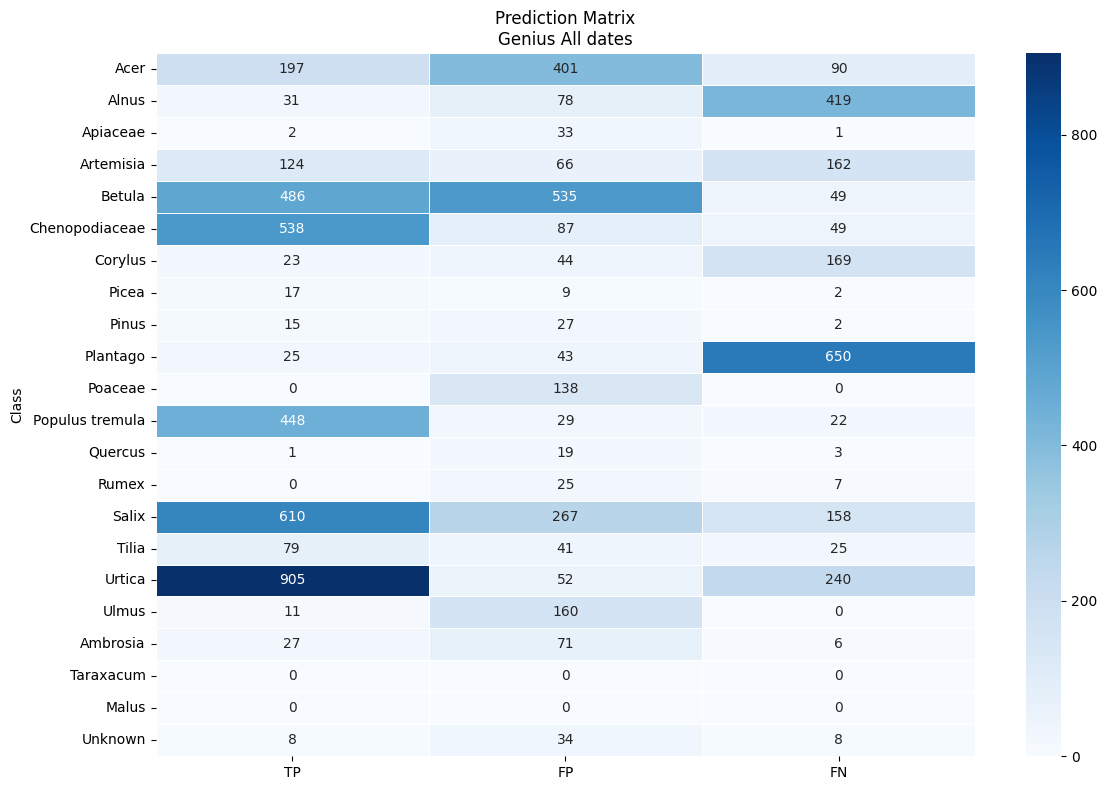

F1 Score: 0.6269553689792311


In [9]:
full_confusion_matrices_df = None

for date_idx in model_prediction_df.index:
    prediction:dict = model_prediction_df.loc[date_idx].to_dict()
    groundtruth:dict = expert_estimation_df.loc[date_idx].to_dict()
    assert len(prediction) > 0
    assert len(groundtruth) > 0

    cf_df = analyze_performance_sample_data(groundtruth, prediction, "Genius " + date_idx, all_classes=all_classes)
    if full_confusion_matrices_df is None:
        full_confusion_matrices_df = cf_df
    else:
        full_confusion_matrices_df += cf_df
plot_confusion_matrix(
        full_confusion_matrices_df.iloc[:, 0:3], subtitle="Genius All dates")

evaluate_aggregate_metrics(full_confusion_matrices_df)

## Classification on Familia level

---Sample test---
True Total objets: 407.0, data: {'Sapindaceae': 0.0, 'Betulaceae': 228.0, 'Ulmaceae': 0.0, 'Fagaceae': 0.0, 'Salicaceae': 178.0, 'Malvaceae': 0.0, 'Pinaceae': 0.0, 'Apiaceae': 0.0, 'Asteraceae': 0.0, 'Rosaceae': 0, 'Poaceae': 0, 'Chenopodiaceae': 0.0, 'Plantaginaceae': 0.0, 'Polygonaceae': 0.0, 'Urticaceae': 1.0}
----------
Pred Total objets: 409.0, data: {'Sapindaceae': 10.0, 'Betulaceae': 207.0, 'Ulmaceae': 2.0, 'Fagaceae': 1.0, 'Salicaceae': 172.0, 'Malvaceae': 0.0, 'Pinaceae': 4.0, 'Apiaceae': 0.0, 'Asteraceae': 6.0, 'Rosaceae': 0, 'Poaceae': 2.0, 'Chenopodiaceae': 3.0, 'Plantaginaceae': 0.0, 'Polygonaceae': 2.0, 'Urticaceae': 0.0}
---Sample test---
True Total objets: 178.0, data: {'Sapindaceae': 0.0, 'Betulaceae': 96.0, 'Ulmaceae': 0.0, 'Fagaceae': 0.0, 'Salicaceae': 82.0, 'Malvaceae': 0.0, 'Pinaceae': 0.0, 'Apiaceae': 0.0, 'Asteraceae': 0.0, 'Rosaceae': 0, 'Poaceae': 0, 'Chenopodiaceae': 0.0, 'Plantaginaceae': 0.0, 'Polygonaceae': 0.0, 'Urticaceae': 0.0}
-------

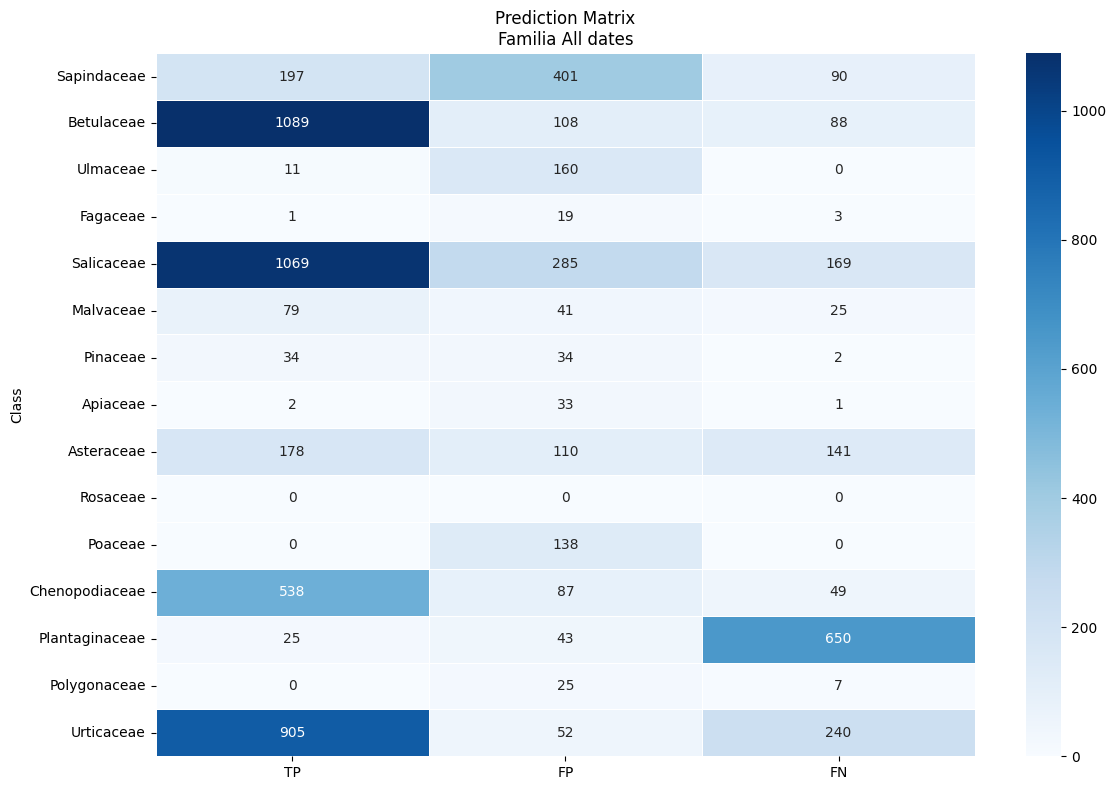

F1 Score: 0.7334103224660211


In [10]:
full_confusion_matrices_df = None

for date_idx in model_prediction_df.index:
    prediction:dict = model_prediction_df.loc[date_idx].to_dict()
    groundtruth:dict = expert_estimation_df.loc[date_idx].to_dict()
    assert len(prediction) > 0
    assert len(groundtruth) > 0

    cf_df = analyze_performance_sample_data(groundtruth, prediction,  "Familia " + date_idx, all_classes=species_by_familia.keys(), mapper=species_by_familia)
    if full_confusion_matrices_df is None:
        full_confusion_matrices_df = cf_df
    else:
        full_confusion_matrices_df += cf_df
plot_confusion_matrix(
        full_confusion_matrices_df.iloc[:, 0:3], subtitle="Familia All dates")

evaluate_aggregate_metrics(full_confusion_matrices_df)

## Classification on Ordo level

---Sample test---
True Total objets: 407.0, data: {'Sapindales': 0.0, 'Fagales': 228.0, 'Rosales': 1.0, 'Malpighiales': 178.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}
----------
Pred Total objets: 409.0, data: {'Sapindales': 10.0, 'Fagales': 208.0, 'Rosales': 2.0, 'Malpighiales': 172.0, 'Malvales': 0.0, 'Pinales': 4.0, 'Apiales': 0.0, 'Asterales': 6.0, 'Poales': 2.0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}


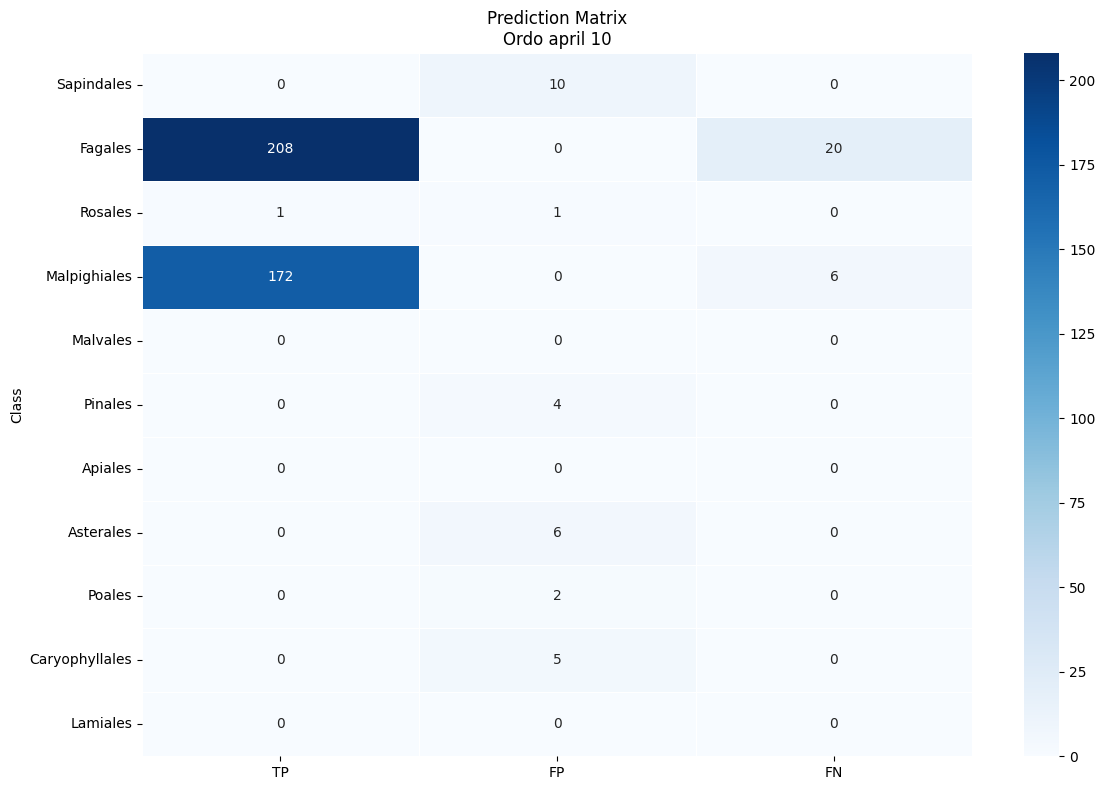

Fagales 0.912
Rosales 1.0
Malpighiales 0.966
---Sample test---
True Total objets: 178.0, data: {'Sapindales': 0.0, 'Fagales': 96.0, 'Rosales': 0.0, 'Malpighiales': 82.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}
----------
Pred Total objets: 192.0, data: {'Sapindales': 2.0, 'Fagales': 90.0, 'Rosales': 5.0, 'Malpighiales': 80.0, 'Malvales': 3.0, 'Pinales': 3.0, 'Apiales': 0.0, 'Asterales': 6.0, 'Poales': 1.0, 'Caryophyllales': 2.0, 'Lamiales': 0.0}


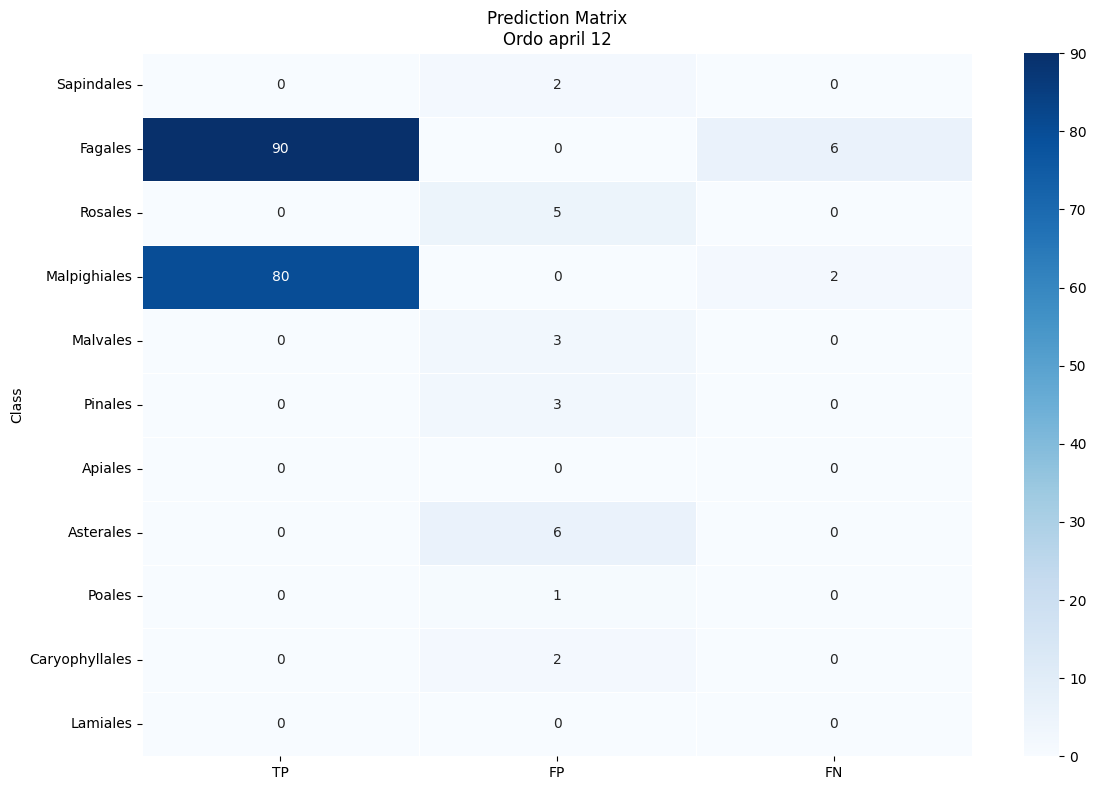

Fagales 0.938
Malpighiales 0.976
---Sample test---
True Total objets: 135.0, data: {'Sapindales': 0.0, 'Fagales': 72.0, 'Rosales': 0.0, 'Malpighiales': 61.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 1.0, 'Poales': 0, 'Caryophyllales': 0.0, 'Lamiales': 0.0}
----------
Pred Total objets: 159.0, data: {'Sapindales': 2.0, 'Fagales': 74.0, 'Rosales': 2.0, 'Malpighiales': 63.0, 'Malvales': 1.0, 'Pinales': 6.0, 'Apiales': 0.0, 'Asterales': 10.0, 'Poales': 0.0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}


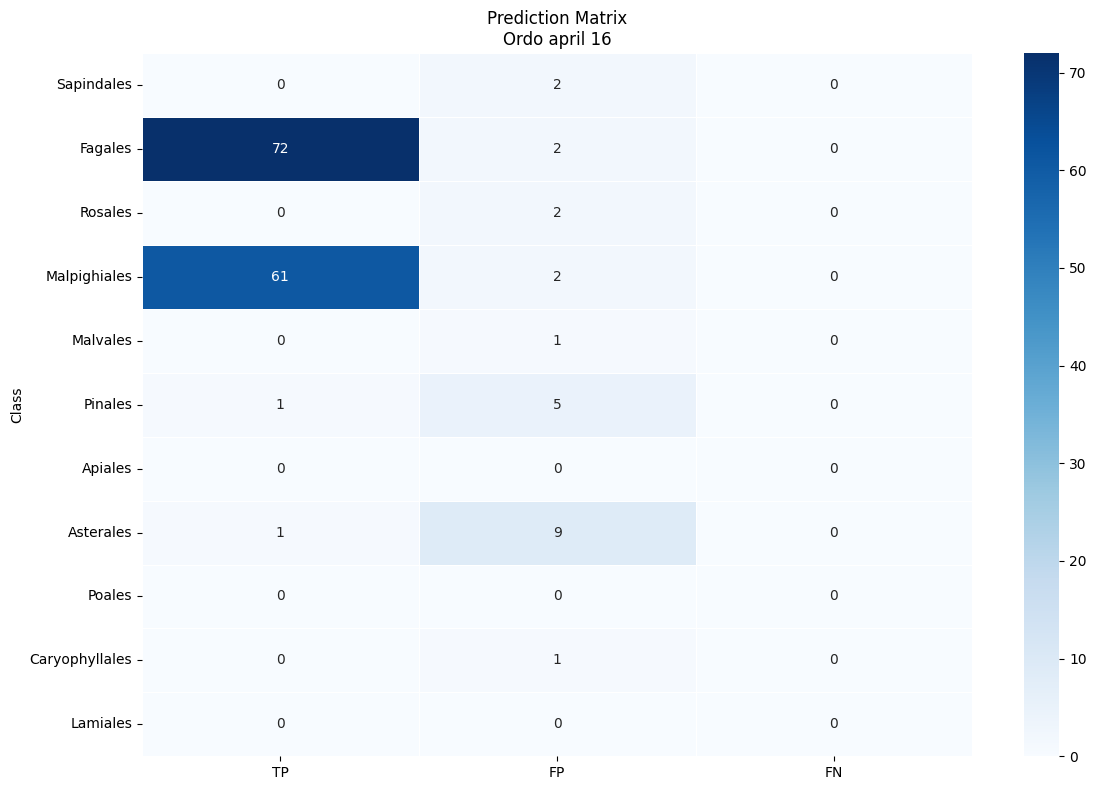

Fagales 1.0
Malpighiales 1.0
Pinales 1.0
Asterales 1.0
---Sample test---
True Total objets: 390.0, data: {'Sapindales': 0.0, 'Fagales': 236.0, 'Rosales': 0.0, 'Malpighiales': 153.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}
----------
Pred Total objets: 377.0, data: {'Sapindales': 3.0, 'Fagales': 203.0, 'Rosales': 6.0, 'Malpighiales': 138.0, 'Malvales': 4.0, 'Pinales': 4.0, 'Apiales': 0.0, 'Asterales': 7.0, 'Poales': 4.0, 'Caryophyllales': 8.0, 'Lamiales': 0.0}


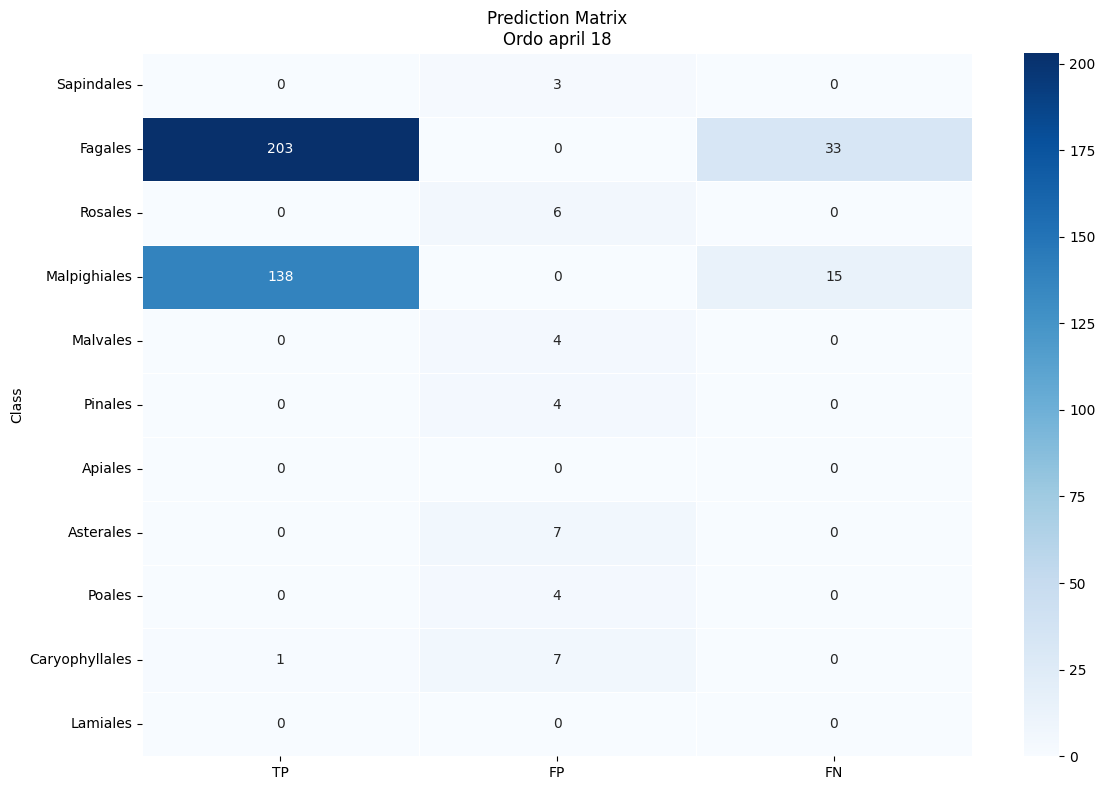

Fagales 0.86
Malpighiales 0.902
Caryophyllales 1.0
---Sample test---
True Total objets: 664.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 543.0, 'Malpighiales': 1.0, 'Malvales': 1.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 7.0, 'Poales': 0, 'Caryophyllales': 111.0, 'Lamiales': 1.0}
----------
Pred Total objets: 750.0, data: {'Sapindales': 5.0, 'Fagales': 13.0, 'Rosales': 526.0, 'Malpighiales': 2.0, 'Malvales': 2.0, 'Pinales': 2.0, 'Apiales': 3.0, 'Asterales': 8.0, 'Poales': 61.0, 'Caryophyllales': 112.0, 'Lamiales': 16.0}


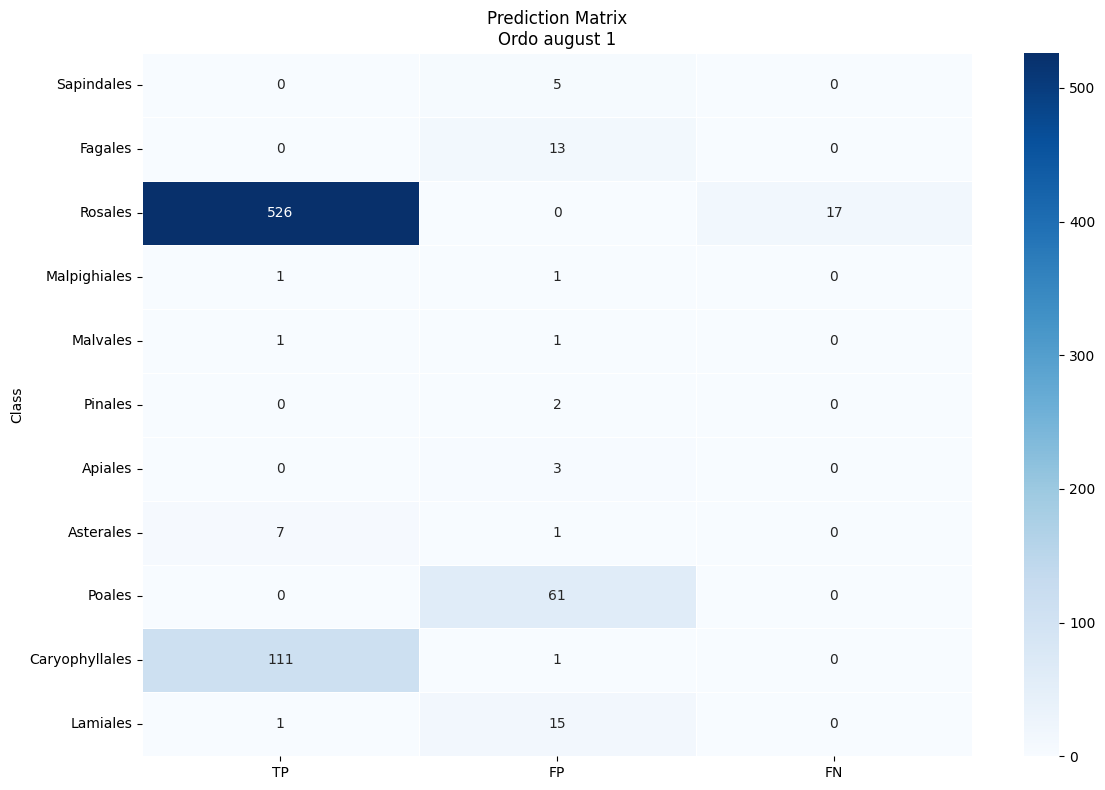

Rosales 0.969
Malpighiales 1.0
Malvales 1.0
Asterales 1.0
Caryophyllales 1.0
Lamiales 1.0
---Sample test---
True Total objets: 223.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 142.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 4.0, 'Poales': 0, 'Caryophyllales': 77.0, 'Lamiales': 0.0}
----------
Pred Total objets: 188.0, data: {'Sapindales': 1.0, 'Fagales': 1.0, 'Rosales': 103.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 1.0, 'Asterales': 7.0, 'Poales': 0.0, 'Caryophyllales': 74.0, 'Lamiales': 1.0}


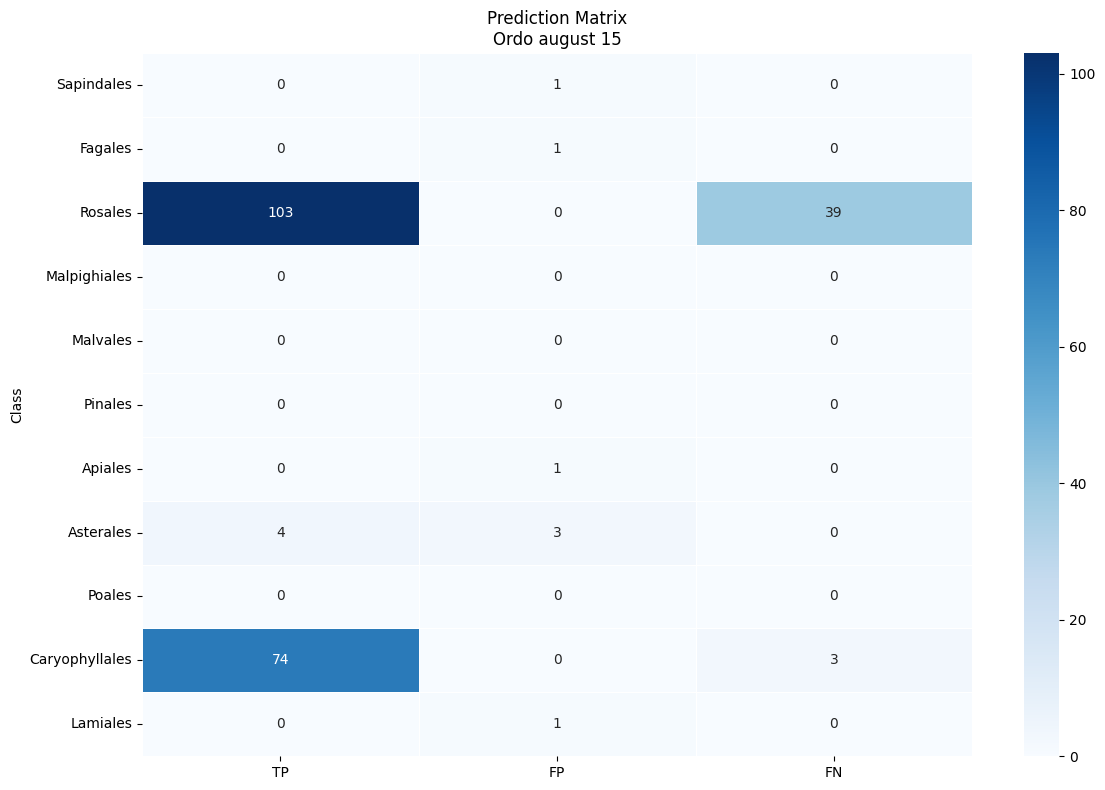

Rosales 0.725
Asterales 1.0
Caryophyllales 0.961
---Sample test---
True Total objets: 221.0, data: {'Sapindales': 0.0, 'Fagales': 1.0, 'Rosales': 52.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 2.0, 'Poales': 0, 'Caryophyllales': 166.0, 'Lamiales': 0.0}
----------
Pred Total objets: 210.0, data: {'Sapindales': 2.0, 'Fagales': 1.0, 'Rosales': 37.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 3.0, 'Apiales': 0.0, 'Asterales': 6.0, 'Poales': 0.0, 'Caryophyllales': 161.0, 'Lamiales': 0.0}


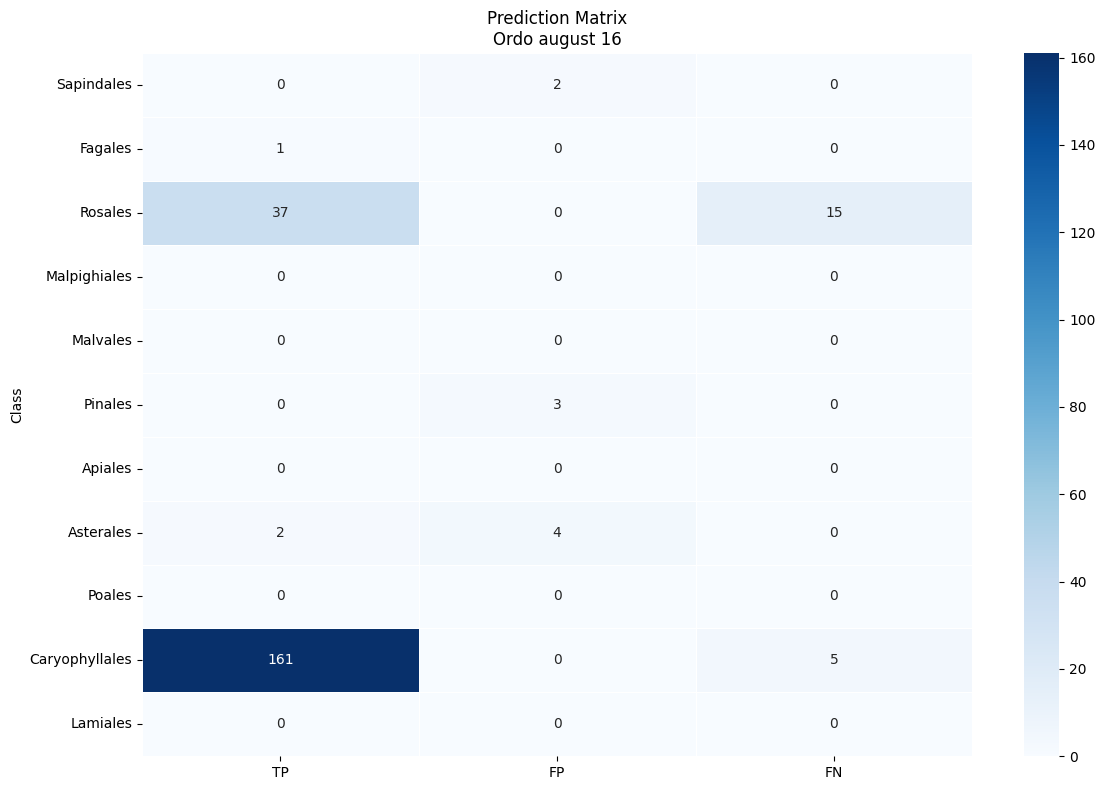

Fagales 1.0
Rosales 0.712
Asterales 1.0
Caryophyllales 0.97
---Sample test---
True Total objets: 204.0, data: {'Sapindales': 0.0, 'Fagales': 1.0, 'Rosales': 60.0, 'Malpighiales': 9.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 20.0, 'Poales': 0, 'Caryophyllales': 113.0, 'Lamiales': 0.0}
----------
Pred Total objets: 206.0, data: {'Sapindales': 11.0, 'Fagales': 11.0, 'Rosales': 59.0, 'Malpighiales': 6.0, 'Malvales': 1.0, 'Pinales': 2.0, 'Apiales': 1.0, 'Asterales': 6.0, 'Poales': 5.0, 'Caryophyllales': 101.0, 'Lamiales': 3.0}


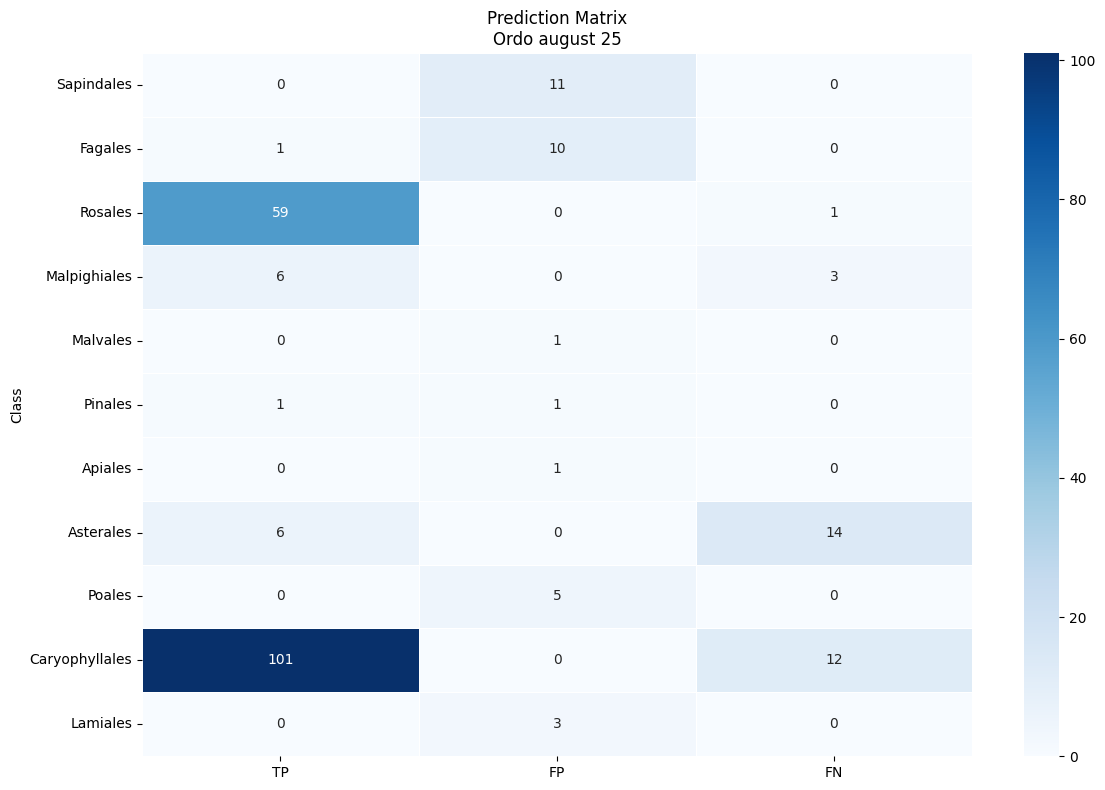

Fagales 1.0
Rosales 0.983
Malpighiales 0.667
Pinales 1.0
Asterales 0.3
Caryophyllales 0.894
---Sample test---
True Total objets: 33.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 13.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 19.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}
----------
Pred Total objets: 62.0, data: {'Sapindales': 10.0, 'Fagales': 11.0, 'Rosales': 16.0, 'Malpighiales': 5.0, 'Malvales': 1.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 14.0, 'Poales': 0.0, 'Caryophyllales': 3.0, 'Lamiales': 2.0}


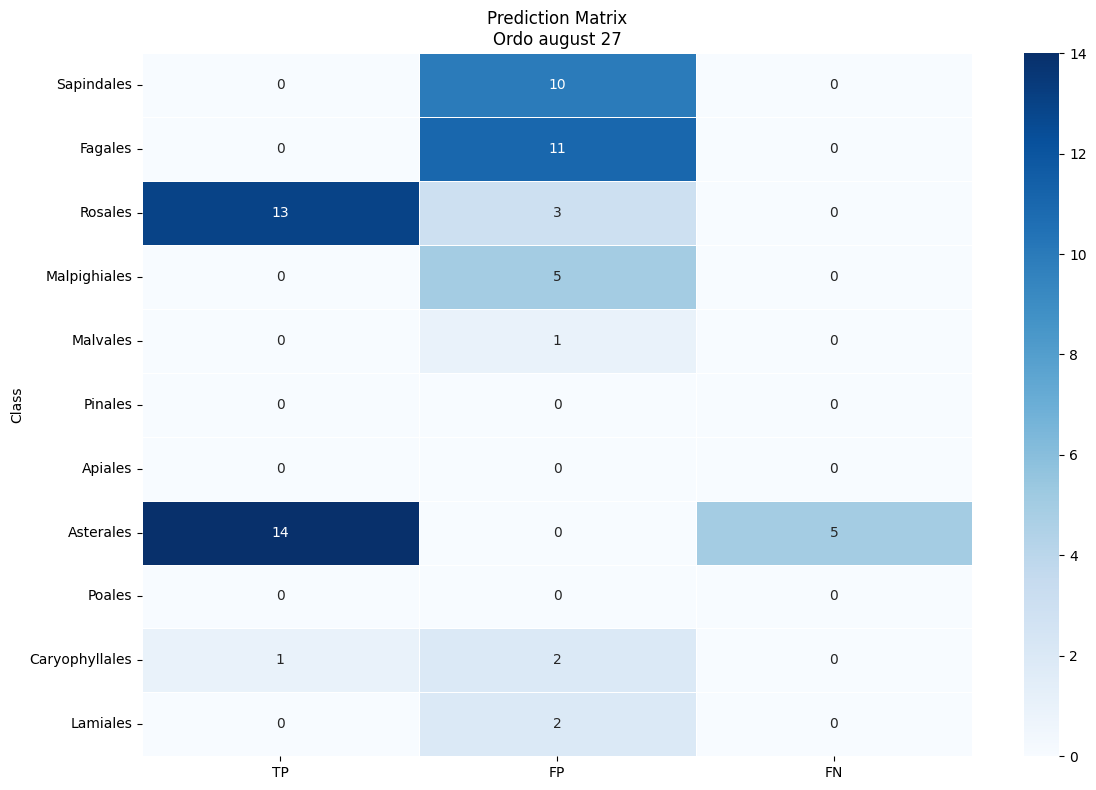

Rosales 1.0
Asterales 0.737
Caryophyllales 1.0
---Sample test---
True Total objets: 98.0, data: {'Sapindales': 0.0, 'Fagales': 5.0, 'Rosales': 14.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 66.0, 'Poales': 0, 'Caryophyllales': 11.0, 'Lamiales': 0.0}
----------
Pred Total objets: 144.0, data: {'Sapindales': 35.0, 'Fagales': 18.0, 'Rosales': 36.0, 'Malpighiales': 2.0, 'Malvales': 5.0, 'Pinales': 3.0, 'Apiales': 0.0, 'Asterales': 34.0, 'Poales': 2.0, 'Caryophyllales': 7.0, 'Lamiales': 2.0}


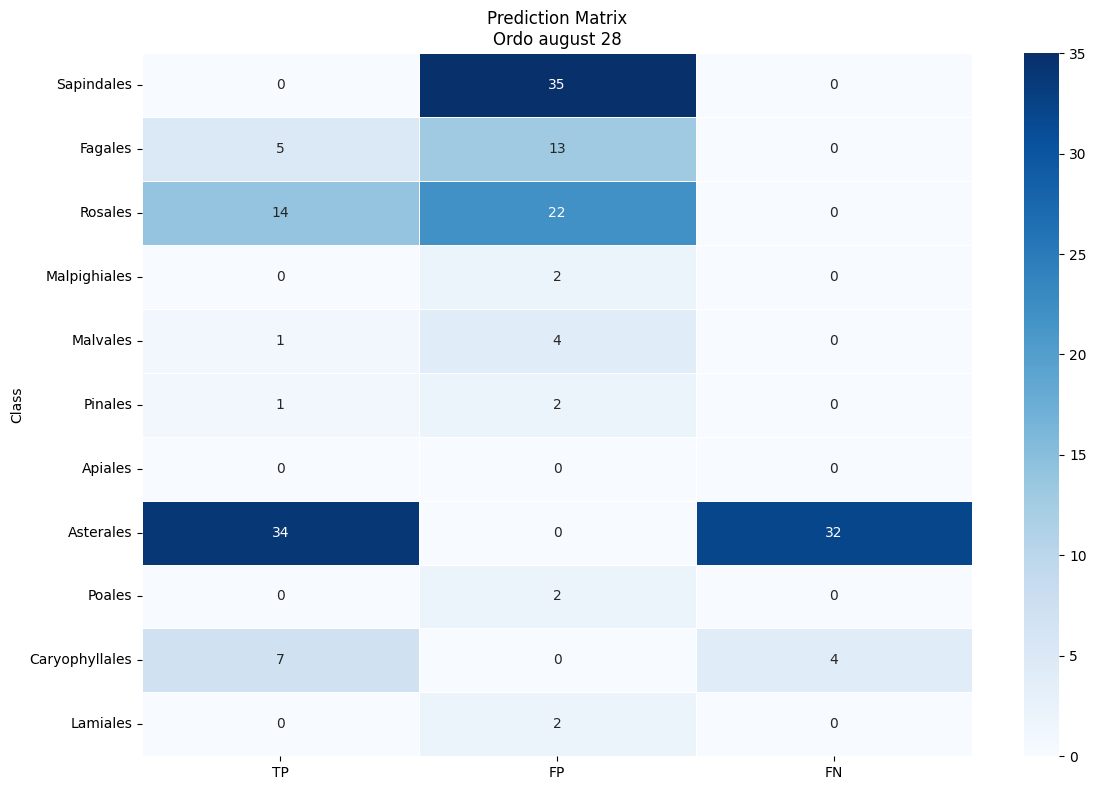

Fagales 1.0
Rosales 1.0
Malvales 1.0
Pinales 1.0
Asterales 0.515
Caryophyllales 0.636
---Sample test---
True Total objets: 54.0, data: {'Sapindales': 0.0, 'Fagales': 2.0, 'Rosales': 15.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 1.0, 'Apiales': 1.0, 'Asterales': 26.0, 'Poales': 0, 'Caryophyllales': 9.0, 'Lamiales': 0.0}
----------
Pred Total objets: 69.0, data: {'Sapindales': 15.0, 'Fagales': 6.0, 'Rosales': 13.0, 'Malpighiales': 1.0, 'Malvales': 2.0, 'Pinales': 0.0, 'Apiales': 2.0, 'Asterales': 18.0, 'Poales': 0.0, 'Caryophyllales': 8.0, 'Lamiales': 4.0}


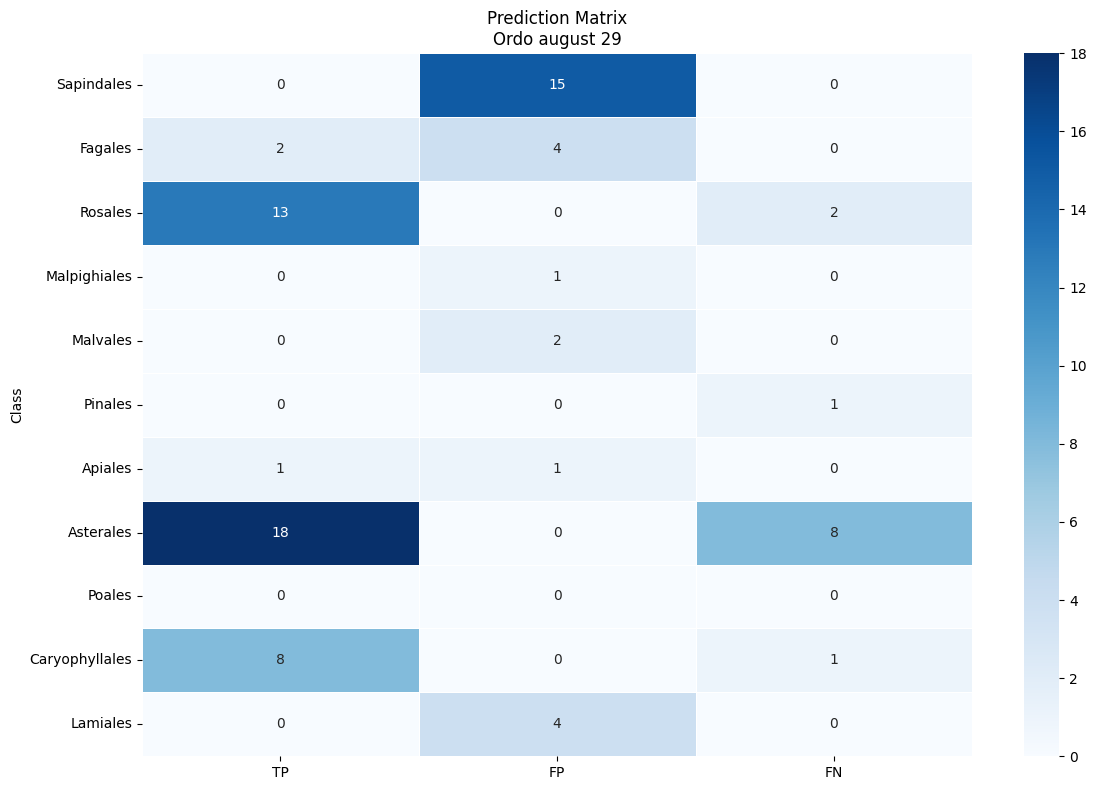

Fagales 1.0
Rosales 0.867
Pinales 0.0
Apiales 1.0
Asterales 0.692
Caryophyllales 0.889
---Sample test---
True Total objets: 172.0, data: {'Sapindales': 0.0, 'Fagales': 4.0, 'Rosales': 27.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 3.0, 'Apiales': 0.0, 'Asterales': 122.0, 'Poales': 0, 'Caryophyllales': 15.0, 'Lamiales': 0.0}
----------
Pred Total objets: 215.0, data: {'Sapindales': 49.0, 'Fagales': 26.0, 'Rosales': 48.0, 'Malpighiales': 2.0, 'Malvales': 5.0, 'Pinales': 4.0, 'Apiales': 2.0, 'Asterales': 58.0, 'Poales': 3.0, 'Caryophyllales': 12.0, 'Lamiales': 6.0}


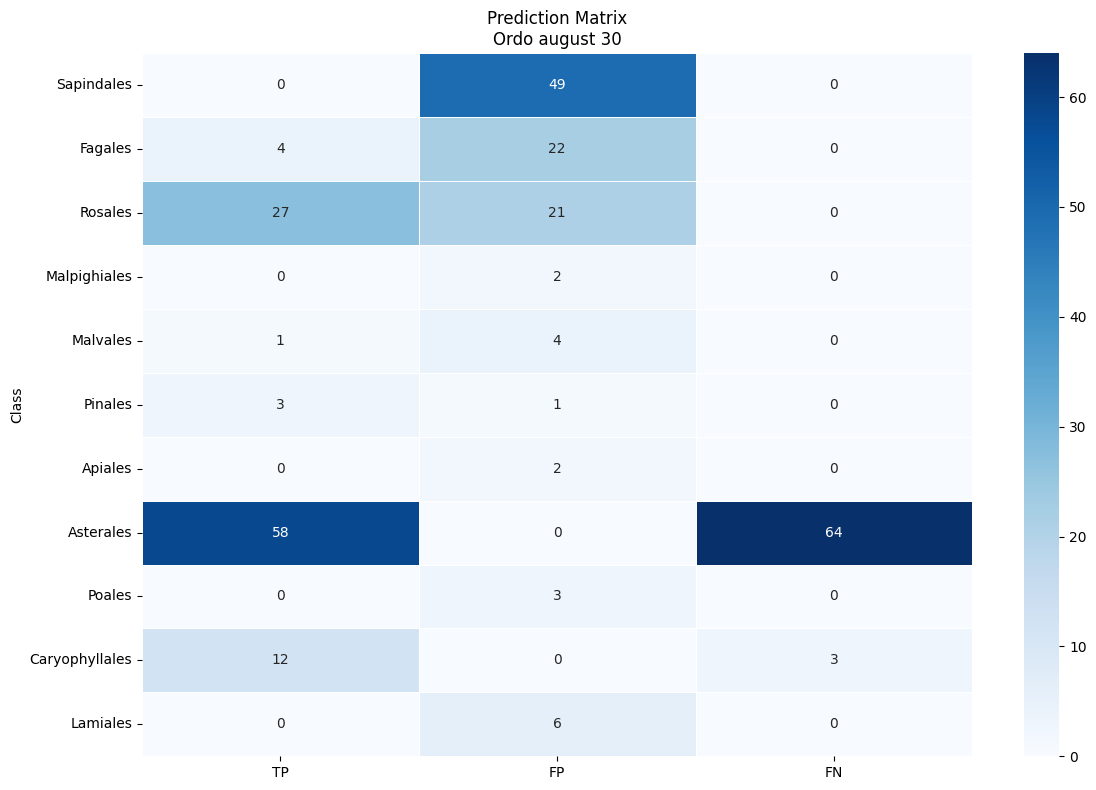

Fagales 1.0
Rosales 1.0
Malvales 1.0
Pinales 1.0
Asterales 0.475
Caryophyllales 0.8
---Sample test---
True Total objets: 65.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 17.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 48.0, 'Lamiales': 0.0}
----------
Pred Total objets: 48.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 13.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 2.0, 'Poales': 0.0, 'Caryophyllales': 33.0, 'Lamiales': 0.0}


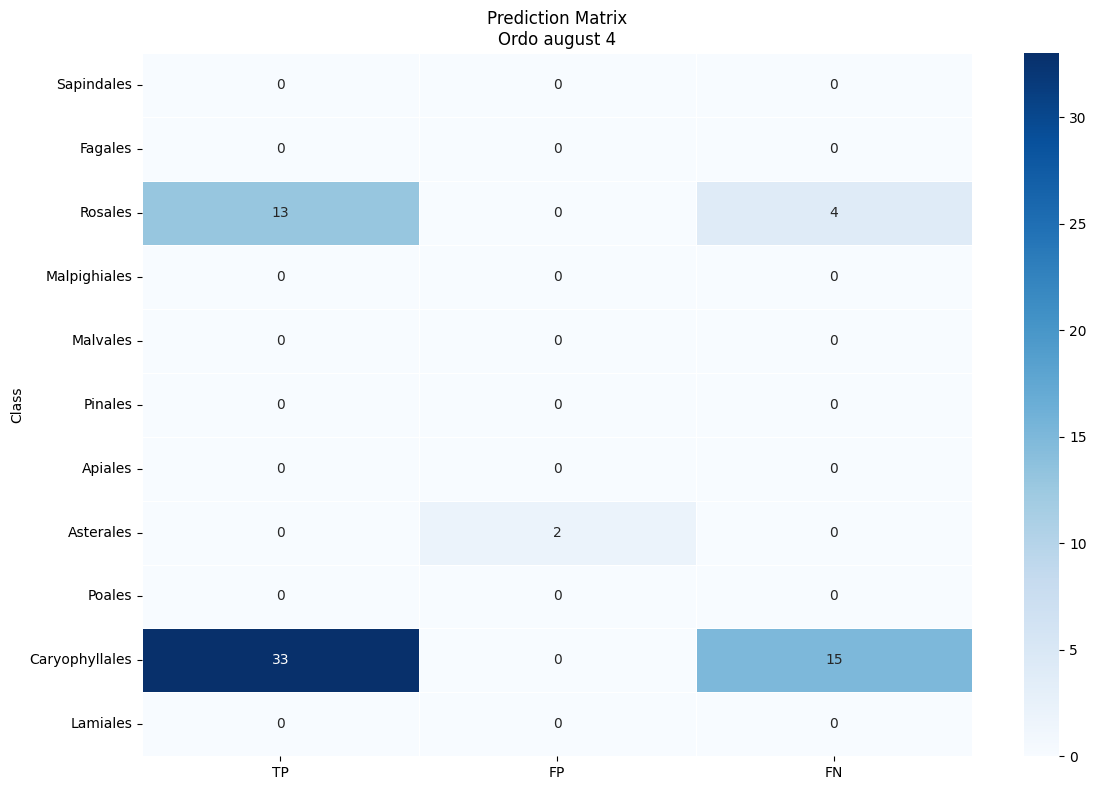

Rosales 0.765
Caryophyllales 0.688
---Sample test---
True Total objets: 79.0, data: {'Sapindales': 0.0, 'Fagales': 3.0, 'Rosales': 37.0, 'Malpighiales': 1.0, 'Malvales': 30.0, 'Pinales': 4.0, 'Apiales': 1.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 3.0, 'Lamiales': 0.0}
----------
Pred Total objets: 61.0, data: {'Sapindales': 3.0, 'Fagales': 11.0, 'Rosales': 4.0, 'Malpighiales': 3.0, 'Malvales': 20.0, 'Pinales': 6.0, 'Apiales': 0.0, 'Asterales': 4.0, 'Poales': 7.0, 'Caryophyllales': 2.0, 'Lamiales': 1.0}


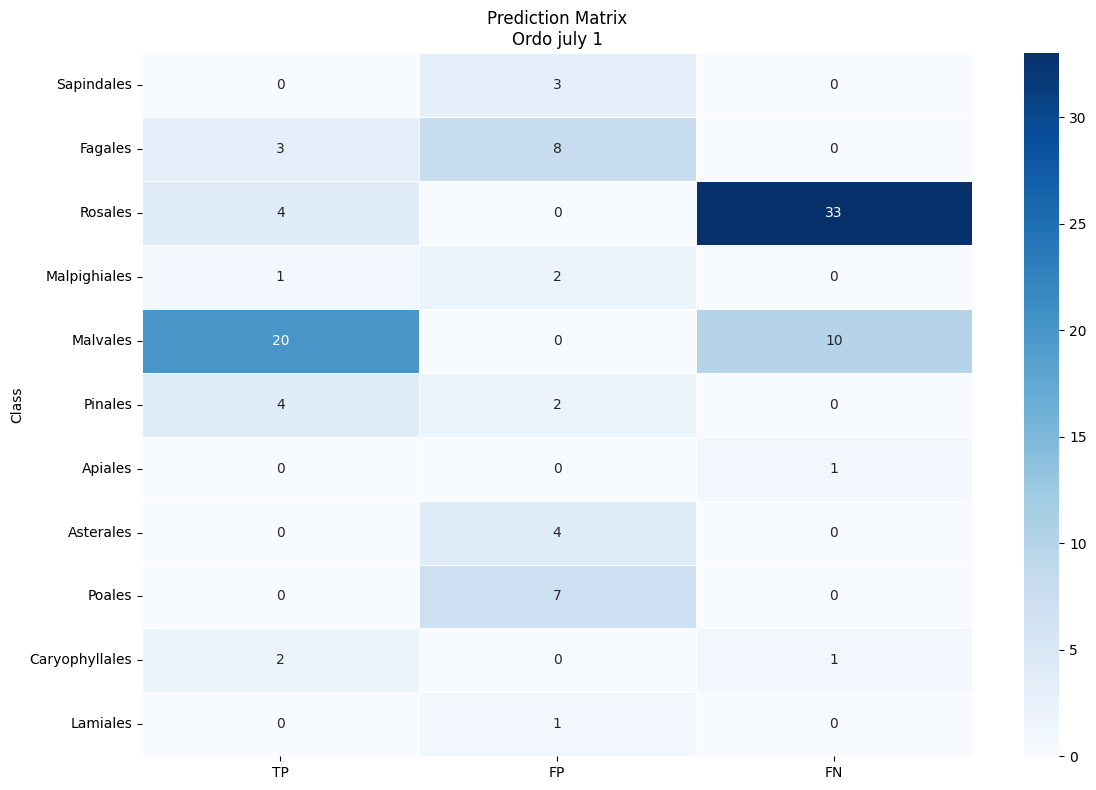

Fagales 1.0
Rosales 0.108
Malpighiales 1.0
Malvales 0.667
Pinales 1.0
Apiales 0.0
Caryophyllales 0.667
---Sample test---
True Total objets: 111.0, data: {'Sapindales': 0.0, 'Fagales': 6.0, 'Rosales': 57.0, 'Malpighiales': 2.0, 'Malvales': 36.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 9.0, 'Lamiales': 1.0}
----------
Pred Total objets: 65.0, data: {'Sapindales': 2.0, 'Fagales': 5.0, 'Rosales': 9.0, 'Malpighiales': 10.0, 'Malvales': 26.0, 'Pinales': 1.0, 'Apiales': 0.0, 'Asterales': 4.0, 'Poales': 5.0, 'Caryophyllales': 3.0, 'Lamiales': 0.0}


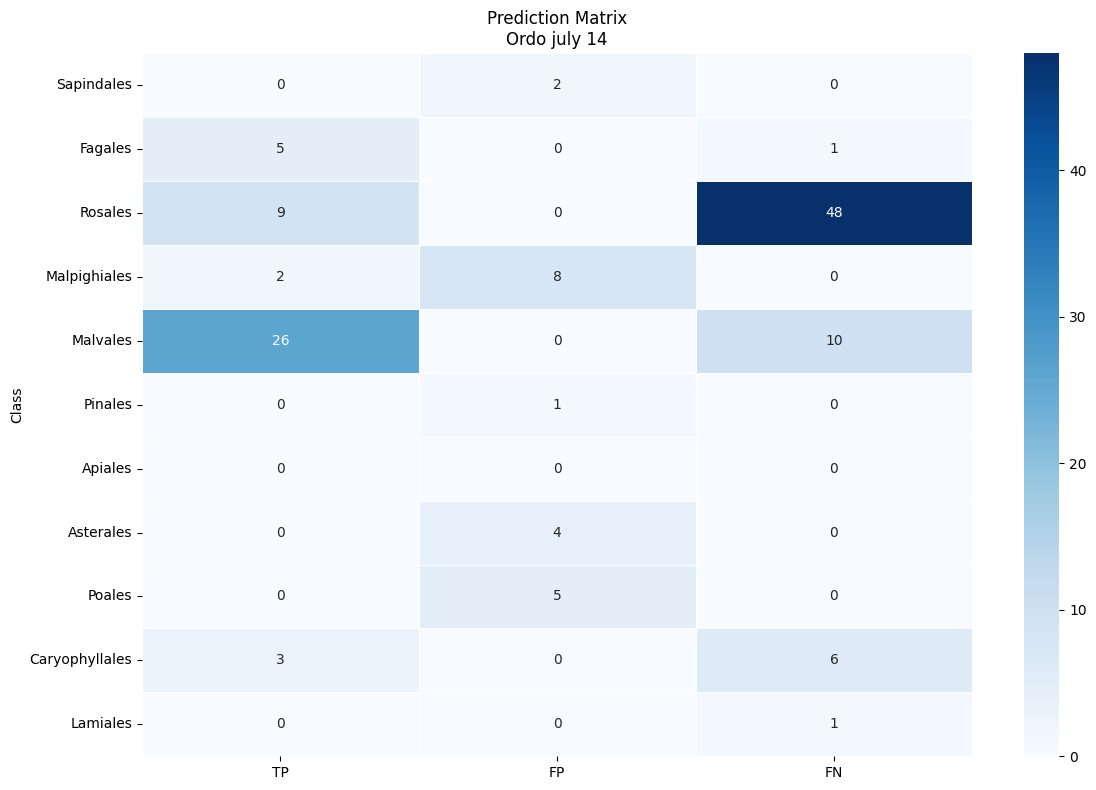

Fagales 0.833
Rosales 0.158
Malpighiales 1.0
Malvales 0.722
Caryophyllales 0.333
Lamiales 0.0
---Sample test---
True Total objets: 97.0, data: {'Sapindales': 0.0, 'Fagales': 12.0, 'Rosales': 39.0, 'Malpighiales': 0.0, 'Malvales': 33.0, 'Pinales': 3.0, 'Apiales': 0.0, 'Asterales': 0.0, 'Poales': 0, 'Caryophyllales': 6.0, 'Lamiales': 4.0}
----------
Pred Total objets: 68.0, data: {'Sapindales': 5.0, 'Fagales': 10.0, 'Rosales': 4.0, 'Malpighiales': 11.0, 'Malvales': 28.0, 'Pinales': 2.0, 'Apiales': 1.0, 'Asterales': 0.0, 'Poales': 2.0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}


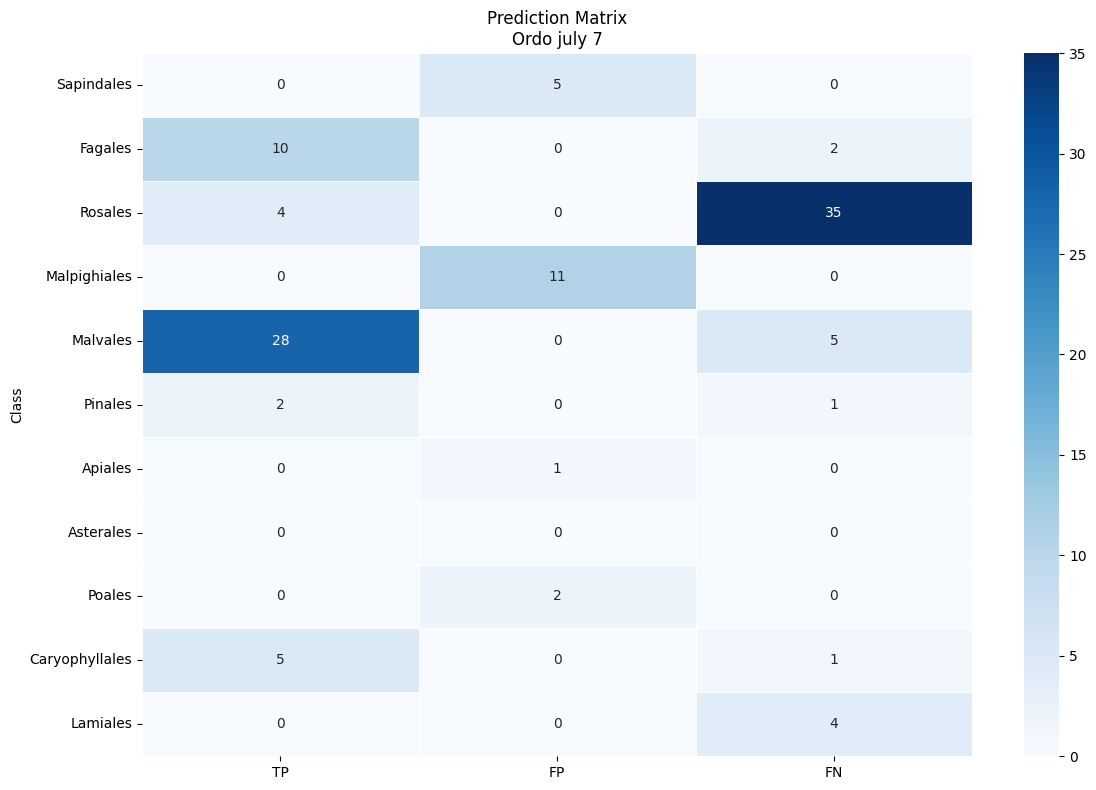

Fagales 0.833
Rosales 0.103
Malvales 0.848
Pinales 0.667
Caryophyllales 0.833
Lamiales 0.0
---Sample test---
True Total objets: 299.0, data: {'Sapindales': 5.0, 'Fagales': 8.0, 'Rosales': 33.0, 'Malpighiales': 2.0, 'Malvales': 0.0, 'Pinales': 2.0, 'Apiales': 0.0, 'Asterales': 1.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 247.0}
----------
Pred Total objets: 329.0, data: {'Sapindales': 107.0, 'Fagales': 15.0, 'Rosales': 45.0, 'Malpighiales': 86.0, 'Malvales': 2.0, 'Pinales': 2.0, 'Apiales': 4.0, 'Asterales': 7.0, 'Poales': 26.0, 'Caryophyllales': 31.0, 'Lamiales': 4.0}


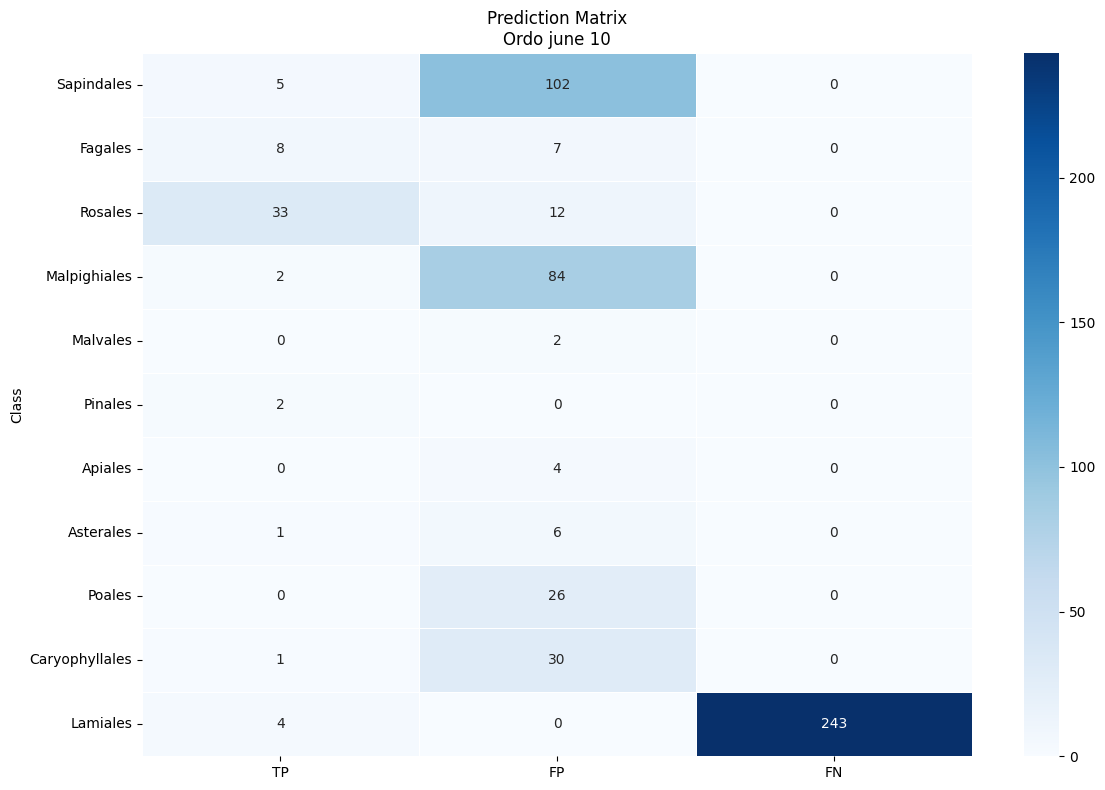

Sapindales 1.0
Fagales 1.0
Rosales 1.0
Malpighiales 1.0
Pinales 1.0
Asterales 1.0
Caryophyllales 1.0
Lamiales 0.016
---Sample test---
True Total objets: 372.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 24.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 5.0, 'Poales': 0, 'Caryophyllales': 3.0, 'Lamiales': 340.0}
----------
Pred Total objets: 381.0, data: {'Sapindales': 87.0, 'Fagales': 10.0, 'Rosales': 65.0, 'Malpighiales': 153.0, 'Malvales': 0.0, 'Pinales': 5.0, 'Apiales': 2.0, 'Asterales': 4.0, 'Poales': 6.0, 'Caryophyllales': 33.0, 'Lamiales': 16.0}


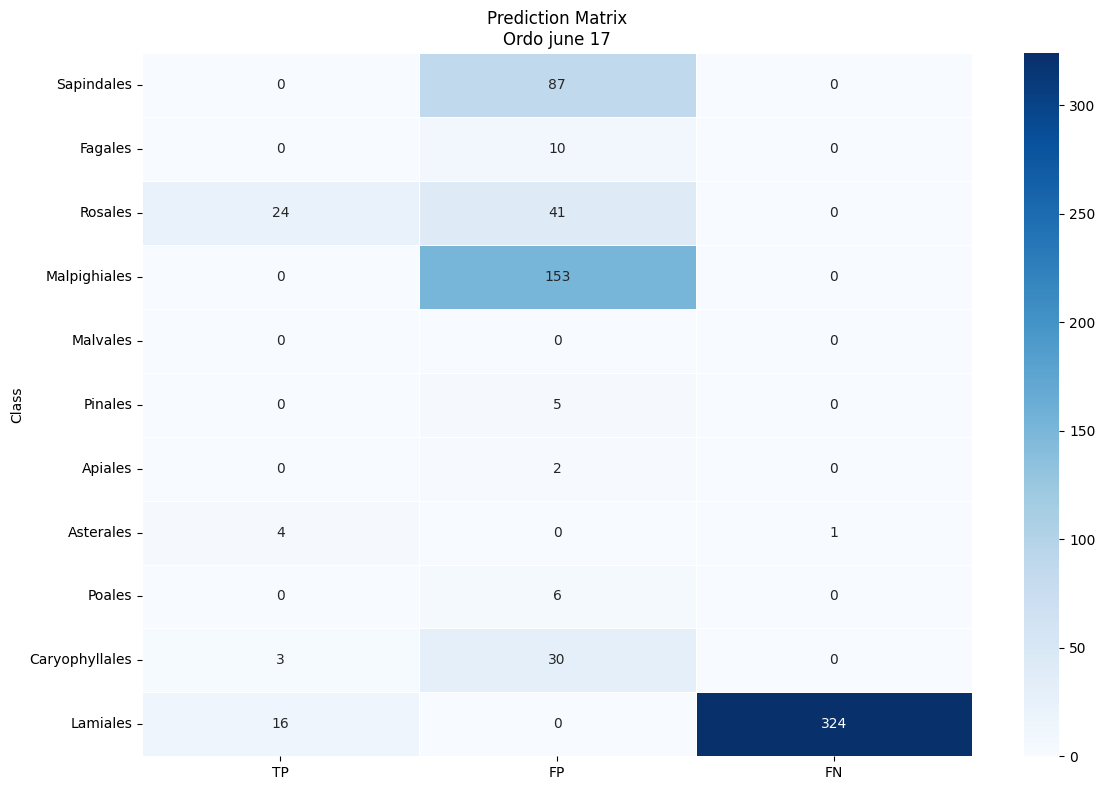

Rosales 1.0
Asterales 0.8
Caryophyllales 1.0
Lamiales 0.047
---Sample test---
True Total objets: 159.0, data: {'Sapindales': 0.0, 'Fagales': 22.0, 'Rosales': 44.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 7.0, 'Poales': 0, 'Caryophyllales': 4.0, 'Lamiales': 82.0}
----------
Pred Total objets: 169.0, data: {'Sapindales': 49.0, 'Fagales': 17.0, 'Rosales': 54.0, 'Malpighiales': 7.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 2.0, 'Asterales': 7.0, 'Poales': 12.0, 'Caryophyllales': 17.0, 'Lamiales': 4.0}


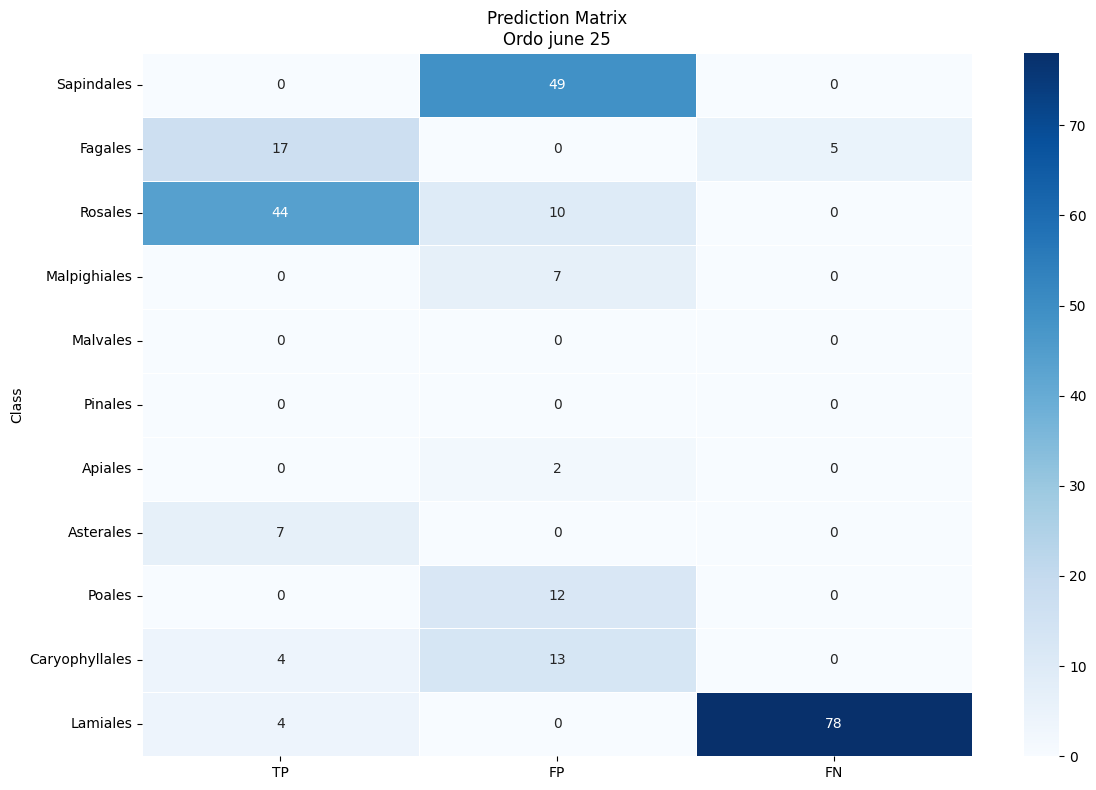

Fagales 0.773
Rosales 1.0
Asterales 1.0
Caryophyllales 1.0
Lamiales 0.049
---Sample test---
True Total objets: 1457.0, data: {'Sapindales': 228.0, 'Fagales': 448.0, 'Rosales': 10.0, 'Malpighiales': 749.0, 'Malvales': 1.0, 'Pinales': 19.0, 'Apiales': 0.0, 'Asterales': 1.0, 'Poales': 0, 'Caryophyllales': 1.0, 'Lamiales': 0.0}
----------
Pred Total objets: 1369.0, data: {'Sapindales': 151.0, 'Fagales': 460.0, 'Rosales': 40.0, 'Malpighiales': 606.0, 'Malvales': 1.0, 'Pinales': 19.0, 'Apiales': 10.0, 'Asterales': 57.0, 'Poales': 0.0, 'Caryophyllales': 19.0, 'Lamiales': 6.0}


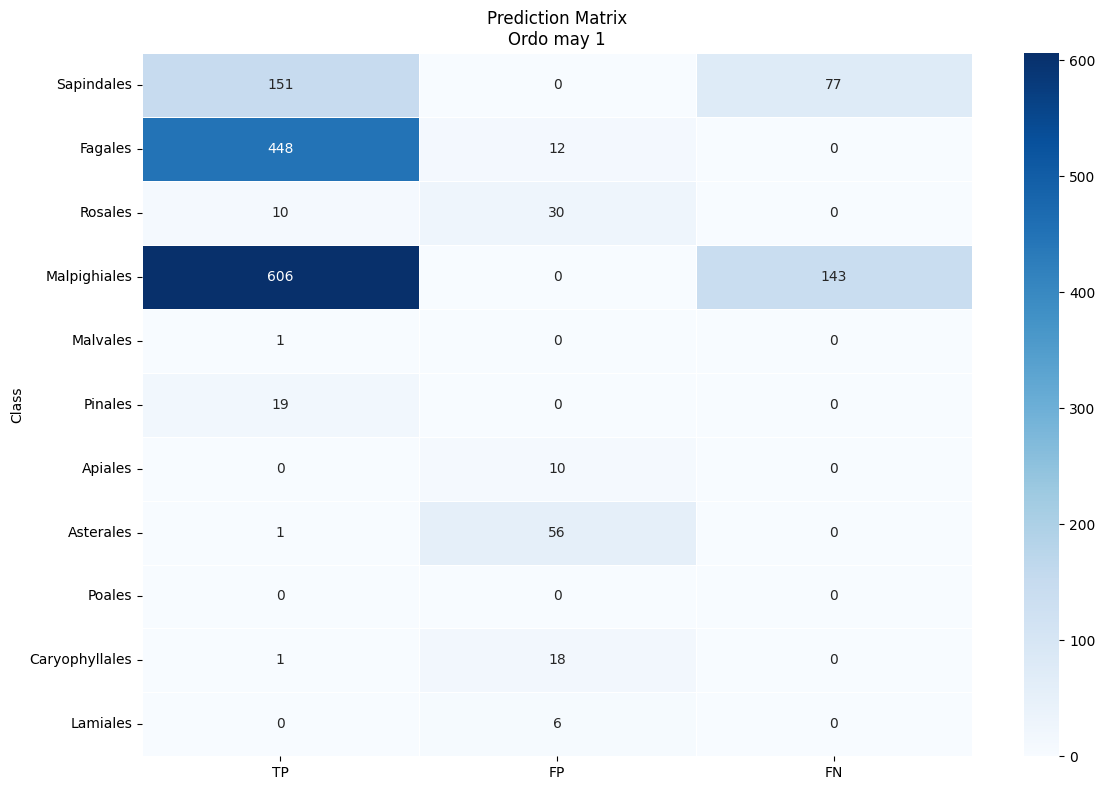

Sapindales 0.662
Fagales 1.0
Rosales 1.0
Malpighiales 0.809
Malvales 1.0
Pinales 1.0
Asterales 1.0
Caryophyllales 1.0
---Sample test---
True Total objets: 80.0, data: {'Sapindales': 27.0, 'Fagales': 35.0, 'Rosales': 10.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 3.0, 'Poales': 0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}
----------
Pred Total objets: 75.0, data: {'Sapindales': 14.0, 'Fagales': 18.0, 'Rosales': 12.0, 'Malpighiales': 3.0, 'Malvales': 16.0, 'Pinales': 0.0, 'Apiales': 4.0, 'Asterales': 5.0, 'Poales': 0.0, 'Caryophyllales': 2.0, 'Lamiales': 1.0}


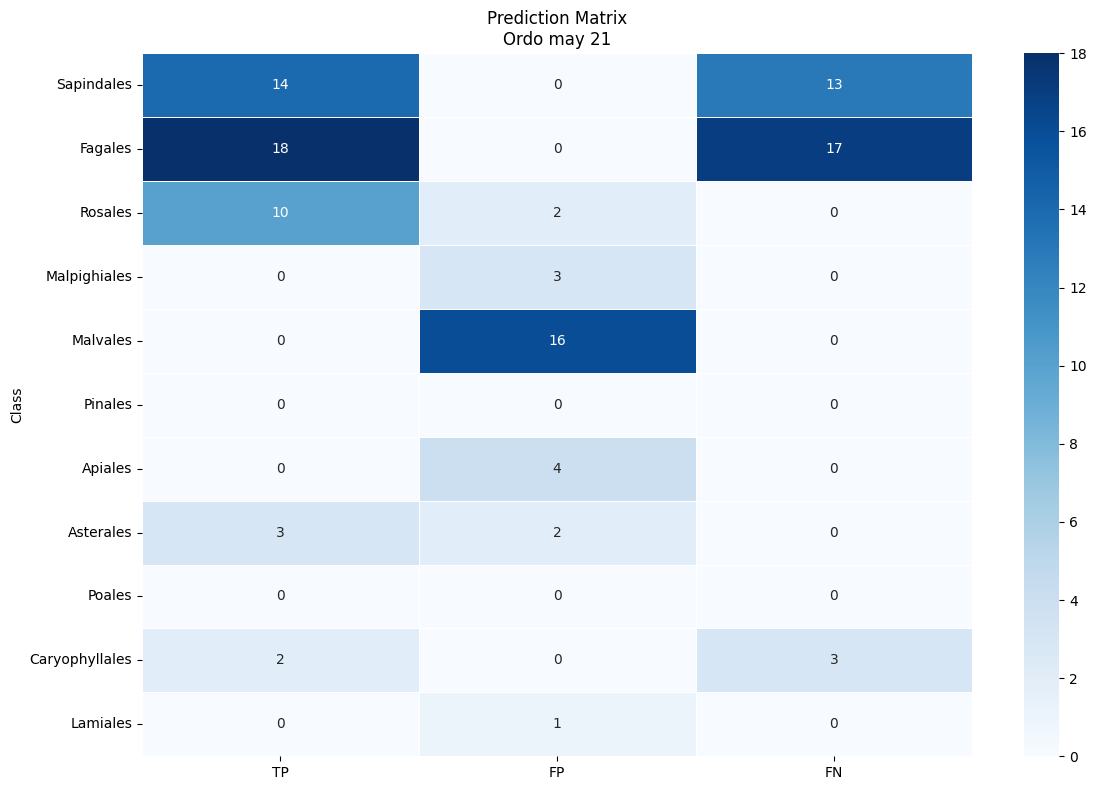

Sapindales 0.519
Fagales 0.514
Rosales 1.0
Asterales 1.0
Caryophyllales 0.4
---Sample test---
True Total objets: 31.0, data: {'Sapindales': 0.0, 'Fagales': 0.0, 'Rosales': 4.0, 'Malpighiales': 0.0, 'Malvales': 0.0, 'Pinales': 0.0, 'Apiales': 0.0, 'Asterales': 22.0, 'Poales': 0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}
----------
Pred Total objets: 54.0, data: {'Sapindales': 8.0, 'Fagales': 5.0, 'Rosales': 16.0, 'Malpighiales': 2.0, 'Malvales': 1.0, 'Pinales': 0.0, 'Apiales': 2.0, 'Asterales': 10.0, 'Poales': 2.0, 'Caryophyllales': 6.0, 'Lamiales': 2.0}


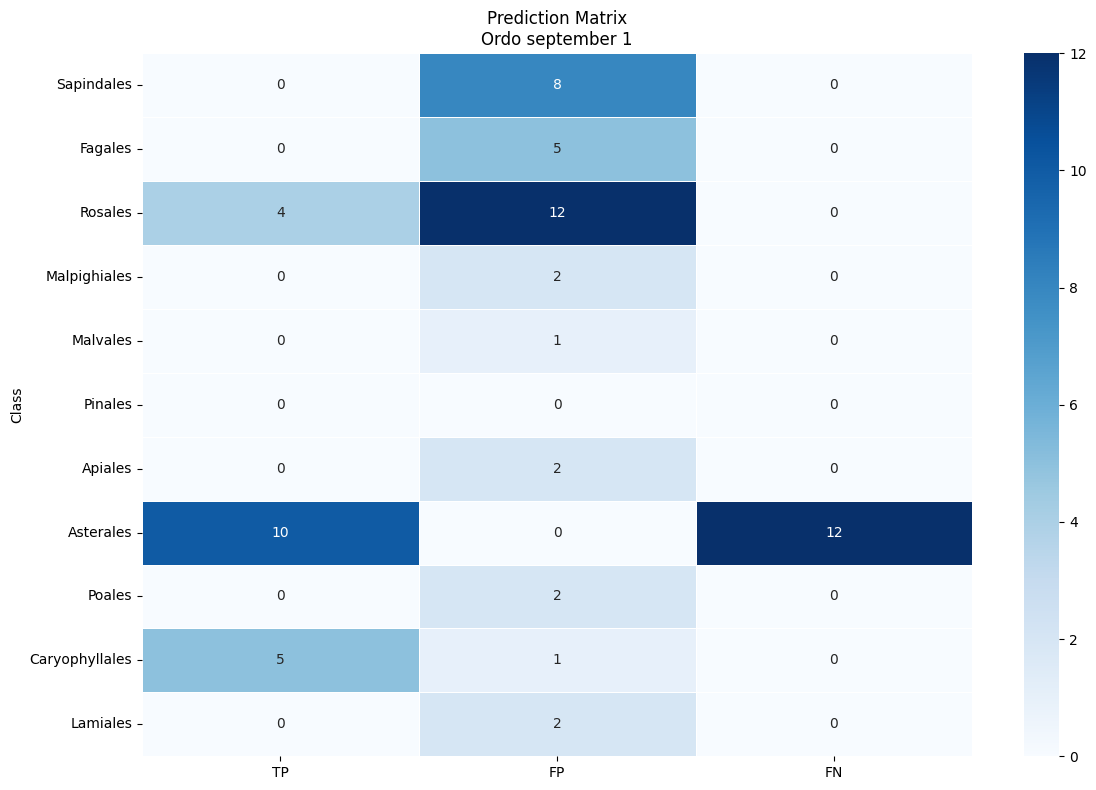

Rosales 1.0
Asterales 0.455
Caryophyllales 1.0
---Sample test---
True Total objets: 64.0, data: {'Sapindales': 27.0, 'Fagales': 2.0, 'Rosales': 14.0, 'Malpighiales': 0.0, 'Malvales': 1.0, 'Pinales': 1.0, 'Apiales': 1.0, 'Asterales': 13.0, 'Poales': 0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}
----------
Pred Total objets: 64.0, data: {'Sapindales': 27.0, 'Fagales': 4.0, 'Rosales': 13.0, 'Malpighiales': 2.0, 'Malvales': 2.0, 'Pinales': 2.0, 'Apiales': 1.0, 'Asterales': 8.0, 'Poales': 0.0, 'Caryophyllales': 5.0, 'Lamiales': 0.0}


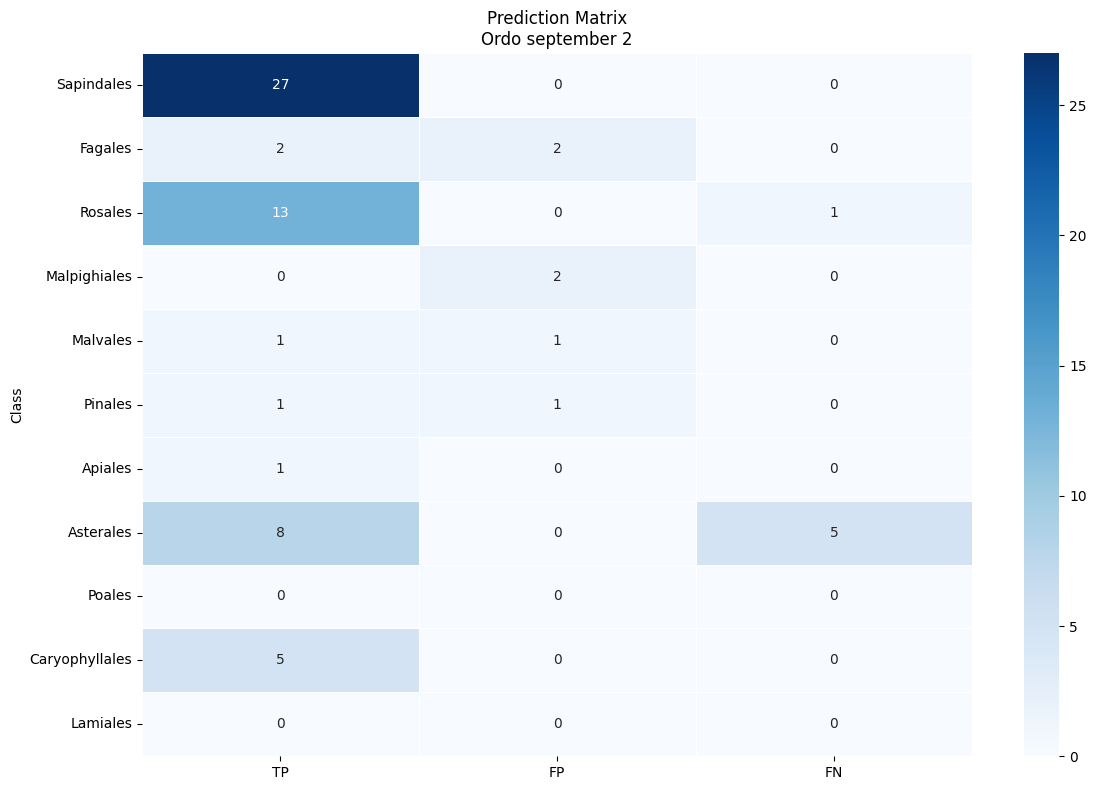

Sapindales 1.0
Fagales 1.0
Rosales 0.929
Malvales 1.0
Pinales 1.0
Apiales 1.0
Asterales 0.615
Caryophyllales 1.0


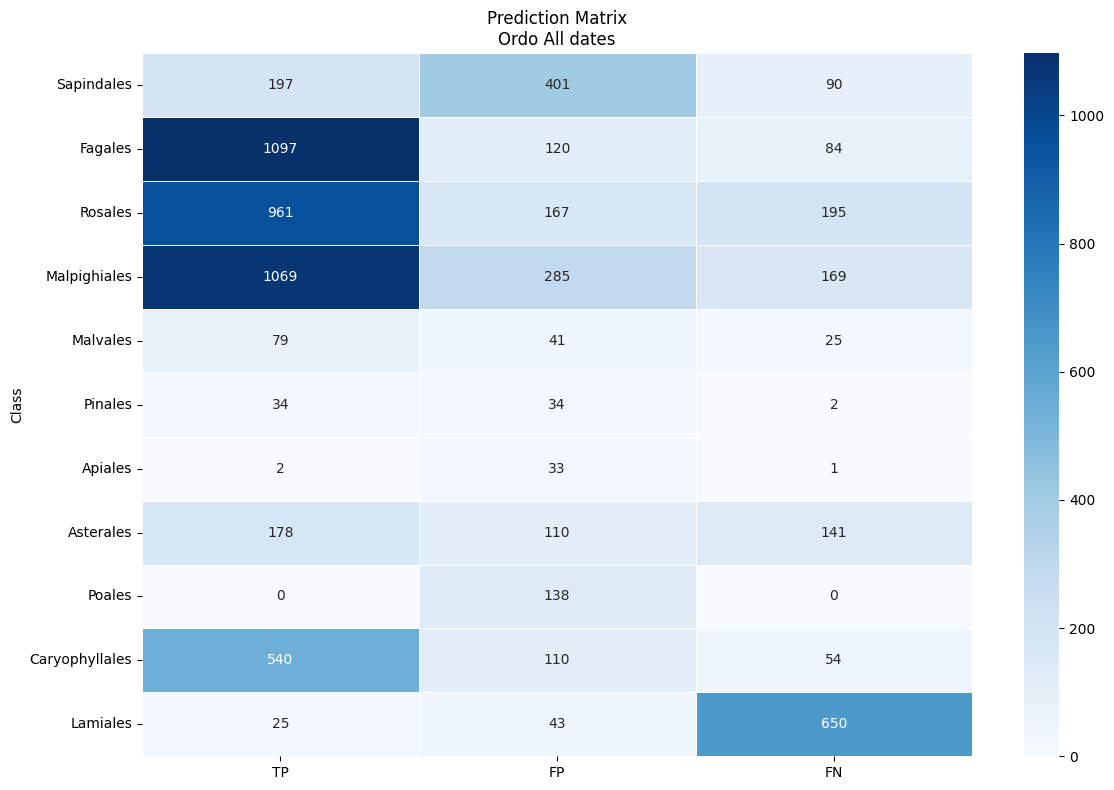

F1 Score: 0.7430043528471173


In [11]:
full_confusion_matrices_df = None

for date_idx in model_prediction_df.index:
    prediction:dict = model_prediction_df.loc[date_idx].to_dict()
    groundtruth:dict = expert_estimation_df.loc[date_idx].to_dict()
    assert len(prediction) > 0
    assert len(groundtruth) > 0

    cf_df = analyze_performance_sample_data(groundtruth, prediction, "Ordo " + date_idx, all_classes=species_by_ordo.keys(), mapper=species_by_ordo, plot=True)
    if full_confusion_matrices_df is None:
        full_confusion_matrices_df = cf_df
    else:
        full_confusion_matrices_df += cf_df
plot_confusion_matrix(
        full_confusion_matrices_df.iloc[:, 0:3], subtitle="Ordo All dates")

evaluate_aggregate_metrics(full_confusion_matrices_df)